# Step 7 — Docking on the dopamine D2 receptor (AutoDock Vina)

Prepare and dock a ligand against the human D2 dopamine receptor (DRD2).

Activate the project's Vina environment, then run:
    conda install -c conda-forge vina meeko rdkit biopython pdbfixer openmm
    run all cells of this notebook

When prompted, enter the path to a ligand .sdf, .mol, or .smi file.

In [6]:
from __future__ import annotations

import contextlib
import math
import shutil
import subprocess
import sys
import sysconfig
import urllib.error
import urllib.request
from pathlib import Path
import sys
import numpy
print(sys.executable)
print(sys.version)

/Users/bartrabelink/miniforge3/envs/acmdd/bin/python
3.14.8 | packaged by conda-forge | (main, Oct  7 2026, 00:15:59) [Clang 20.1.8 ]


## Settings

Receptor (PDB 6CM4), co-crystallised ligand used to place the docking box (risperidone, `8NU`), and Vina settings.

In [7]:
ROOT = Path(_dh[-1]).parent  # ACMDD_D2_Receptor/ (this notebook lives in Workflow_steps/)

RUN_DIR = ROOT / "docking" / "runs"

PDB_ID = "6CM4"

SHARED_RECEPTOR_DIR = ROOT / "docking" / "prepared" / PDB_ID

PDB_URL = f"https://files.rcsb.org/download/{PDB_ID}.cif"

RISPERIDONE_COMPONENT_ID = "8NU"

# 6CM4 contains DRD2 sequence positions 1-188 and 349-430 separated by a
# T4 lysozyme fusion. Keep only the DRD2 portions of the construct.
DRD2_SEQUENCE_RANGES = ((1, 188), (349, 430))

BOX_PADDING_ANGSTROM = 8.0

EXHAUSTIVENESS = 8

NUM_MODES = 9

## Check dependencies

Checks that Vina, Meeko, RDKit, Biopython, PDBFixer and OpenMM are installed and finds the Meeko preparation tools.

In [8]:
def require_dependencies() -> dict[str, str]:
    if sys.platform == "win32":
        raise RuntimeError(
            "This docking script uses AutoDock Vina's Python bindings, which are "
            "supported on Linux and macOS, not native Windows. Run it in Ubuntu "
            "under WSL instead. In your WSL terminal, activate the drd2-vina "
            "environment and run:\n"
            "  conda install -c conda-forge vina meeko rdkit biopython "
            "pdbfixer openmm\n"
            "Then run this script from the WSL terminal."
        )

    try:
        from Bio.PDB.MMCIF2Dict import MMCIF2Dict  # noqa: F401
        from openmm.app import PDBFile  # noqa: F401
        from pdbfixer import PDBFixer  # noqa: F401
        from rdkit import Chem  # noqa: F401
        from rdkit.Chem import AllChem  # noqa: F401
        from vina import Vina  # noqa: F401
    except ImportError as exc:
        raise RuntimeError(
            "A required package is missing. Activate the Vina environment and run:\n"
            "  conda install -c conda-forge vina meeko rdkit biopython pdbfixer openmm\n"
            "Then run this script again with `python vina_autodock.py`."
        ) from exc

    scripts_dir = Path(sysconfig.get_path("scripts"))
    tools = {}
    for tool in ("mk_prepare_receptor.py", "mk_prepare_ligand.py"):
        executable = shutil.which(tool)
        if executable is None:
            candidate = scripts_dir / (
                f"{tool}.exe" if sys.platform == "win32" else tool
            )
            if candidate.is_file():
                executable = str(candidate)
        if executable is not None:
            tools[tool] = executable
    missing_tools = set(("mk_prepare_receptor.py", "mk_prepare_ligand.py")) - tools.keys()
    if missing_tools:
        raise RuntimeError(
            "Meeko preparation tools were not found. Activate the Vina environment and run:\n"
            "  conda install -c conda-forge meeko\n"
            "Then run this script again from that environment."
        )
    return tools

## Download and read the structure

In [9]:
def cif_values(cif: dict, key: str) -> list[str]:
    value = cif.get(key, [])
    if isinstance(value, str):
        return [value]
    return list(value)

In [10]:
def download_structure(path: Path) -> None:
    if path.exists():
        return
    path.parent.mkdir(parents=True, exist_ok=True)
    request = urllib.request.Request(
        PDB_URL,
        headers={"User-Agent": "DRD2-Vina-docking/1.0"},
    )
    try:
        with urllib.request.urlopen(request, timeout=60) as response:
            path.write_bytes(response.read())
    except (urllib.error.URLError, TimeoutError) as exc:
        raise RuntimeError(
            f"Could not download DRD2 structure {PDB_ID} from RCSB PDB: {exc}"
        ) from exc

## Extract the D2 receptor and define the docking box

Keeps only the DRD2 parts of 6CM4 (removes the T4 lysozyme fusion) and builds the docking box around the co-crystallised risperidone.

In [11]:
def make_receptor_and_box(cif_path: Path, receptor_pdb: Path) -> tuple[list[float], list[float]]:
    from Bio.PDB.MMCIF2Dict import MMCIF2Dict

    cif = MMCIF2Dict(str(cif_path))
    component_ids = set(cif_values(cif, "_chem_comp.id"))
    if RISPERIDONE_COMPONENT_ID not in component_ids:
        raise ValueError(
            f"Expected risperidone component {RISPERIDONE_COMPONENT_ID} was not "
            f"found in PDB {PDB_ID}; stopping rather than guessing a docking box."
        )

    fields = {
        "record": "_atom_site.group_PDB",
        "entity": "_atom_site.label_entity_id",
        "label_chain": "_atom_site.label_asym_id",
        "sequence": "_atom_site.label_seq_id",
        "component": "_atom_site.label_comp_id",
        "atom": "_atom_site.label_atom_id",
        "altloc": "_atom_site.label_alt_id",
        "residue": "_atom_site.auth_seq_id",
        "insertion": "_atom_site.pdbx_PDB_ins_code",
        "x": "_atom_site.Cartn_x",
        "y": "_atom_site.Cartn_y",
        "z": "_atom_site.Cartn_z",
        "occupancy": "_atom_site.occupancy",
        "b_factor": "_atom_site.B_iso_or_equiv",
        "element": "_atom_site.type_symbol",
    }
    atom_columns = {name: cif_values(cif, key) for name, key in fields.items()}
    atom_count = len(atom_columns["record"])
    if not atom_count or any(len(values) != atom_count for values in atom_columns.values()):
        raise ValueError(f"PDB {PDB_ID} has incomplete atom records.")

    alternate_occupancy: dict[tuple[str, str, str], dict[str, float]] = {}
    for index in range(atom_count):
        if atom_columns["record"][index] != "ATOM":
            continue
        altloc = atom_columns["altloc"][index]
        if altloc in (".", "?", " "):
            continue
        residue_key = (
            atom_columns["entity"][index],
            atom_columns["label_chain"][index],
            atom_columns["sequence"][index],
        )
        occupancies = alternate_occupancy.setdefault(residue_key, {})
        occupancies[altloc] = occupancies.get(altloc, 0.0) + float(
            atom_columns["occupancy"][index]
        )
    preferred_altloc = {
        residue_key: max(occupancies, key=occupancies.get)
        for residue_key, occupancies in alternate_occupancy.items()
    }

    native_ligand_points: list[tuple[float, float, float]] = []
    receptor_lines = ["REMARK DRD2 receptor prepared from RCSB PDB 6CM4\n"]
    serial = 1
    for index in range(atom_count):
        record = atom_columns["record"][index]
        component = atom_columns["component"][index]
        element = atom_columns["element"][index].strip().upper()
        point = tuple(
            float(atom_columns[axis][index]) for axis in ("x", "y", "z")
        )

        if (
            record == "HETATM"
            and component == RISPERIDONE_COMPONENT_ID
            and element != "H"
        ):
            native_ligand_points.append(point)

        if record != "ATOM" or atom_columns["entity"][index] != "1":
            continue
        try:
            sequence_number = int(atom_columns["sequence"][index])
        except ValueError:
            continue
        segment = next(
            (
                segment_index
                for segment_index, (start, end) in enumerate(DRD2_SEQUENCE_RANGES)
                if start <= sequence_number <= end
            ),
            None,
        )
        if segment is None:
            continue

        altloc = atom_columns["altloc"][index]
        if altloc not in (".", "?", " "):
            residue_key = (
                atom_columns["entity"][index],
                atom_columns["label_chain"][index],
                atom_columns["sequence"][index],
            )
            if altloc != preferred_altloc.get(residue_key):
                continue
        residue_id = int(atom_columns["residue"][index])
        insertion = atom_columns["insertion"][index]
        if insertion in (".", "?", " "):
            insertion = " "
        chain = "A" if segment == 0 else "B"
        atom_name = atom_columns["atom"][index]
        atom_field = (
            f"{atom_name:<4s}"
            if len(atom_name) == 4 or atom_name[:1].isdigit()
            else f" {atom_name:<3s}"
        )
        residue_name = component
        x, y, z = point
        occupancy = float(atom_columns["occupancy"][index])
        b_factor = float(atom_columns["b_factor"][index])
        receptor_lines.append(
            f"ATOM  {serial:5d} {atom_field} {residue_name:>3s} {chain}"
            f"{residue_id:4d}{insertion:1s}   {x:8.3f}{y:8.3f}{z:8.3f}"
            f"{occupancy:6.2f}{b_factor:6.2f}          {element:>2s}\n"
        )
        serial += 1

    if not native_ligand_points:
        raise ValueError(f"No co-crystallized risperidone coordinates found in {PDB_ID}.")
    if serial <= 2:
        raise ValueError(f"No DRD2 protein atoms were extracted from PDB {PDB_ID}.")

    receptor_lines.extend(("TER\n", "END\n"))
    receptor_pdb.parent.mkdir(parents=True, exist_ok=True)
    receptor_pdb.write_text("".join(receptor_lines), encoding="ascii")

    axes = list(zip(*native_ligand_points))
    minimum = [min(axis) for axis in axes]
    maximum = [max(axis) for axis in axes]
    center = [(low + high) / 2 for low, high in zip(minimum, maximum)]
    size = [
        high - low + BOX_PADDING_ANGSTROM
        for low, high in zip(minimum, maximum)
    ]
    if not all(math.isfinite(value) for value in center) or not all(
        math.isfinite(value) and value > 0 for value in size
    ):
        raise ValueError("Could not calculate a valid docking box from native risperidone.")
    return center, size

## Repair and prepare the receptor

Rebuilds missing atoms with PDBFixer, relaxes them with a restrained OpenMM minimisation and writes the receptor PDBQT. The prepared receptor is cached in `docking/prepared/6CM4/` and reused for every ligand.

In [12]:
def repair_missing_atoms(receptor_pdb: Path, repaired_pdb: Path) -> None:
    """Rebuild missing atoms and relax the structure with positional restraints."""
    from openmm.app import PDBFile
    from pdbfixer import PDBFixer

    fixer = PDBFixer(filename=str(receptor_pdb))
    fixer.findMissingResidues()
    fixer.missingResidues = {}
    fixer.findNonstandardResidues()
    fixer.replaceNonstandardResidues()
    fixer.findMissingAtoms()
    fixer.addMissingAtoms()

    repaired_pdb.parent.mkdir(parents=True, exist_ok=True)
    with repaired_pdb.open("w", encoding="ascii") as output_file:
        PDBFile.writeFile(
            fixer.topology,
            fixer.positions,
            output_file,
            keepIds=True,
        )
    minimize_repaired_receptor(receptor_pdb, repaired_pdb)
    corrected = correct_terminal_oxygen_geometry(repaired_pdb)
    if corrected:
        print(f"Corrected anomalous terminal oxygen geometry in {corrected} residue(s).")

In [13]:
def prepare_shared_receptor(tools: dict[str, str]) -> tuple[list[float], list[float]]:
    structure_path = SHARED_RECEPTOR_DIR / f"{PDB_ID}.cif"
    receptor_pdb = SHARED_RECEPTOR_DIR / "drd2_clean.pdb"
    repaired_receptor_pdb = SHARED_RECEPTOR_DIR / "drd2_repaired.pdb"
    receptor_pdbqt = SHARED_RECEPTOR_DIR / "drd2.pdbqt"

    download_structure(structure_path)
    center, size = make_receptor_and_box(structure_path, receptor_pdb)
    if all(path.is_file() for path in (repaired_receptor_pdb, receptor_pdbqt)):
        print(f"Reusing shared prepared receptor: {receptor_pdbqt}")
        return center, size

    print("Preparing shared DRD2 receptor for ligand screening...")
    repair_missing_atoms(receptor_pdb, repaired_receptor_pdb)
    run_preparation(
        [
            tools["mk_prepare_receptor.py"],
            "--read_pdb", str(repaired_receptor_pdb),
            "--write_pdbqt", str(receptor_pdbqt),
            "--box_center", *(f"{value:.3f}" for value in center),
            "--box_size", *(f"{value:.3f}" for value in size),
            "--delete_bad_res_from_box_radius", "8",
        ],
        "shared DRD2 receptor",
    )
    return center, size

In [14]:
def minimize_repaired_receptor(
    receptor_pdb: Path,
    repaired_pdb: Path,
) -> None:
    """Relax rebuilt atoms while strongly restraining experimental heavy atoms."""
    import openmm
    from openmm import unit
    from openmm.app import ForceField, Modeller, NoCutoff, PDBFile, Simulation

    original_atoms = set()
    for line in receptor_pdb.read_text(encoding="ascii").splitlines():
        if line.startswith("ATOM  "):
            original_atoms.add(
                (line[21], line[22:26].strip(), line[26], line[12:16].strip())
            )

    pdb = PDBFile(str(repaired_pdb))
    modeller = Modeller(pdb.topology, pdb.positions)
    forcefield = ForceField("amber14-all.xml")
    modeller.addHydrogens(forcefield, pH=7.0)
    system = forcefield.createSystem(
        modeller.topology,
        nonbondedMethod=NoCutoff,
        constraints=None,
    )
    restraints = openmm.CustomExternalForce(
        "0.5*k*((x-x0)^2+(y-y0)^2+(z-z0)^2)"
    )
    for parameter in ("k", "x0", "y0", "z0"):
        restraints.addPerParticleParameter(parameter)

    positions = modeller.positions
    for atom in modeller.topology.atoms():
        if atom.element is None or atom.element.symbol in {"H", "D"}:
            continue
        residue = atom.residue
        atom_key = (
            residue.chain.id,
            residue.id.strip(),
            residue.insertionCode,
            atom.name,
        )
        position = positions[atom.index].value_in_unit(unit.nanometer)
        restraint_strength = 10000.0 if atom_key in original_atoms else 100.0
        restraints.addParticle(
            atom.index,
            [restraint_strength, position.x, position.y, position.z],
        )
    system.addForce(restraints)

    simulation = Simulation(
        modeller.topology,
        system,
        openmm.VerletIntegrator(0.001 * unit.picoseconds),
    )
    simulation.context.setPositions(positions)
    openmm.LocalEnergyMinimizer.minimize(
        simulation.context,
        tolerance=10.0 * unit.kilojoules_per_mole / unit.nanometer,
        maxIterations=1000,
    )
    minimized_positions = simulation.context.getState(getPositions=True).getPositions()
    with repaired_pdb.open("w", encoding="ascii") as output_file:
        PDBFile.writeFile(
            modeller.topology,
            minimized_positions,
            output_file,
            keepIds=True,
        )

    lines = repaired_pdb.read_text(encoding="ascii").splitlines(keepends=True)
    repaired_pdb.write_text(
        "".join(
            line for line in lines
            if not line.startswith(("ATOM  ", "HETATM"))
            or line[76:78].strip().upper() not in {"H", "D"}
        ),
        encoding="ascii",
    )

In [15]:
def correct_terminal_oxygen_geometry(repaired_pdb: Path) -> int:
    """Move mispositioned terminal oxygens away from false RDKit bond distances."""
    lines = repaired_pdb.read_text(encoding="ascii").splitlines(keepends=True)
    residues: dict[tuple[str, str], dict[str, int]] = {}
    for index, line in enumerate(lines):
        if not line.startswith(("ATOM  ", "HETATM")):
            continue
        residue_key = (line[21], line[22:27])
        residues.setdefault(residue_key, {})[line[12:16].strip()] = index

    corrected = 0
    for atoms in residues.values():
        if not all(name in atoms for name in ("CA", "C", "O", "OXT")):
            continue

        def coordinates(atom_name: str) -> tuple[float, float, float]:
            line = lines[atoms[atom_name]]
            return tuple(float(line[start:start + 8]) for start in (30, 38, 46))

        ca, carbonyl_c, oxygen, terminal_oxygen = (
            coordinates(name) for name in ("CA", "C", "O", "OXT")
        )
        if math.dist(ca, terminal_oxygen) >= 1.8:
            continue

        ca_vector = tuple(ca[i] - carbonyl_c[i] for i in range(3))
        oxygen_vector = tuple(oxygen[i] - carbonyl_c[i] for i in range(3))

        def unit(vector: tuple[float, float, float]) -> tuple[float, float, float]:
            magnitude = math.sqrt(sum(value * value for value in vector))
            if magnitude < 1e-8:
                raise ValueError("Could not repair degenerate terminal oxygen geometry.")
            return tuple(value / magnitude for value in vector)

        ca_direction = unit(ca_vector)
        oxygen_direction = unit(oxygen_vector)
        opposite_bisector = tuple(
            -(ca_direction[i] + oxygen_direction[i]) for i in range(3)
        )
        terminal_direction = unit(opposite_bisector)
        repaired_position = tuple(
            carbonyl_c[i] + 1.25 * terminal_direction[i] for i in range(3)
        )

        index = atoms["OXT"]
        lines[index] = (
            lines[index][:30]
            + "".join(f"{value:8.3f}" for value in repaired_position)
            + lines[index][54:]
        )
        corrected += 1

    if corrected:
        repaired_pdb.write_text("".join(lines), encoding="ascii")
    return corrected

## Prepare the ligand

Reads a ligand from `.sdf`, `.mol` or `.smi`, keeps the organic component, adds hydrogens and generates a 3D conformer.

In [16]:
def create_ligand_sdf(source_path: Path, sdf_path: Path) -> None:
    from rdkit import Chem
    from rdkit.Chem import AllChem

    suffix = source_path.suffix.lower()
    molecule = None
    if suffix == ".sdf":
        supplier = Chem.SDMolSupplier(str(source_path), removeHs=False)
        molecule = next((candidate for candidate in supplier if candidate is not None), None)
    elif suffix == ".mol":
        molecule = Chem.MolFromMolFile(str(source_path), removeHs=False)
    elif suffix in (".smi", ".smiles", ".txt"):
        smiles_tokens = source_path.read_text(encoding="utf-8-sig").strip().split()
        if not smiles_tokens:
            raise ValueError(f"No SMILES string found in {source_path}.")
        molecule = Chem.MolFromSmiles(smiles_tokens[0])
        if molecule is None:
            raise ValueError(
                f"Could not parse SMILES token {smiles_tokens[0]!r} from "
                f"{source_path}. Check the file contents and remove any "
                "unsupported characters."
            )
    else:
        raise ValueError("Use a ligand file ending in .sdf, .mol, .smi, .smiles, or .txt.")

    if molecule is None:
        raise ValueError(f"Could not read a valid molecule from {source_path}.")

    fragments = Chem.GetMolFrags(molecule, asMols=True, sanitizeFrags=True)
    if len(fragments) > 1:
        organic_fragments = [
            fragment
            for fragment in fragments
            if any(atom.GetAtomicNum() == 6 for atom in fragment.GetAtoms())
        ]
        if len(organic_fragments) != 1:
            raise ValueError(
                f"Ligand input contains {len(fragments)} disconnected fragments "
                f"and {len(organic_fragments)} carbon-containing components. "
                "Provide a single ligand or a salt with exactly one "
                "carbon-containing component; refusing to guess which component "
                "to dock."
            )

        ignored_fragments = [
            Chem.MolToSmiles(fragment)
            for fragment in fragments
            if fragment is not organic_fragments[0]
        ]
        molecule = organic_fragments[0]
        print(
            "Ignoring disconnected non-carbon fragment(s) for docking: "
            f"{', '.join(ignored_fragments)}. "
            f"Using ligand component {Chem.MolToSmiles(molecule)}."
        )

    molecule = Chem.AddHs(molecule, addCoords=molecule.GetNumConformers() > 0)
    has_3d = (
        molecule.GetNumConformers() > 0
        and molecule.GetConformer().Is3D()
    )
    if not has_3d:
        molecule.RemoveAllConformers()
        if AllChem.EmbedMolecule(molecule, randomSeed=22) != 0:
            raise ValueError("Could not generate a 3D conformer for the ligand.")
        if AllChem.MMFFHasAllMoleculeParams(molecule):
            AllChem.MMFFOptimizeMolecule(molecule)

    sdf_path.parent.mkdir(parents=True, exist_ok=True)
    writer = Chem.SDWriter(str(sdf_path))
    writer.write(molecule)
    writer.close()

In [13]:
def run_preparation(command: list[str], label: str) -> None:
    print(f"Preparing {label}...")
    subprocess.run(command, check=True)

## Docking with AutoDock Vina

In [17]:
def dock(receptor_pdbqt: Path, ligand_pdbqt: Path, output_path: Path,
         log_path: Path, center: list[float], size: list[float]) -> None:
    from vina import Vina

    vina = Vina(sf_name="vina", cpu=0)
    vina.set_receptor(str(receptor_pdbqt))
    vina.set_ligand_from_file(str(ligand_pdbqt))
    vina.compute_vina_maps(center=center, box_size=size)
    with log_path.open("w", encoding="utf-8") as log_file:
        with contextlib.redirect_stdout(log_file):
            vina.dock(exhaustiveness=EXHAUSTIVENESS, n_poses=NUM_MODES)
            vina.write_poses(str(output_path), n_poses=NUM_MODES, overwrite=True)
            scores = vina.score()
    print(f"Best Vina score: {scores[0]:.2f} kcal/mol")

## The ligand to dock

The compound to dock is defined here as a SMILES string, so the notebook records exactly
which molecule was docked. The SMILES below is the top hit from the step 6 ML prediction
(`s_2230__14934458__16949512`, predicted pIC50 8.18).

The SMILES is written to a `.smi` file, because the docking code reads the ligand from a
file. Results are written to `docking/runs/<LIGAND_NAME>/`.

top_hit_s2230_14934458: Cc1nc2n(c(=O)c1CCN1CCN(c3cccc(Cl)c3Cl)CC1)CCCC2


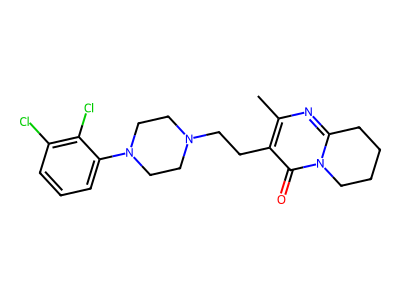

In [14]:
# Ligand to dock: top hit from the step 6 ML prediction
LIGAND_NAME = "top_hit_s2230_14934458"
LIGAND_SMILES = "CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl"

# Write the SMILES to a file, which is what the docking code reads
LIGAND_FILE = ROOT / "docking" / "examples" / "drd2" / f"{LIGAND_NAME}.smi"
LIGAND_FILE.parent.mkdir(parents=True, exist_ok=True)
LIGAND_FILE.write_text(LIGAND_SMILES + "\n", encoding="ascii")

# Show the molecule to confirm the SMILES is the intended compound
from rdkit import Chem
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG, display

molecule = Chem.MolFromSmiles(LIGAND_SMILES)
print(f"{LIGAND_NAME}: {Chem.MolToSmiles(molecule)}")
drawer = rdMolDraw2D.MolDraw2DSVG(400, 300)
drawer.DrawMolecule(molecule)
drawer.FinishDrawing()
display(SVG(drawer.GetDrawingText()))

In [17]:
def main(ligand_path) -> int:
    try:
        tools = require_dependencies()
        raw_path = str(ligand_path).strip().strip('"')
        if not raw_path:
            raise ValueError("No ligand file was provided.")
        ligand_source = Path(raw_path.replace("\\", "/")).expanduser().resolve()
        if not ligand_source.is_file():
            raise FileNotFoundError(f"Ligand file not found: {ligand_source}")

        run_name = ligand_source.stem
        run_dir = RUN_DIR / run_name
        run_dir.mkdir(parents=True, exist_ok=True)

        center, size = prepare_shared_receptor(tools)
        for filename in (
            f"{PDB_ID}.cif",
            "drd2_clean.pdb",
            "drd2_repaired.pdb",
            "drd2.pdbqt",
        ):
            shutil.copyfile(SHARED_RECEPTOR_DIR / filename, run_dir / filename)

        receptor_pdbqt = run_dir / "drd2.pdbqt"
        ligand_sdf = run_dir / "ligand_3d.sdf"
        ligand_pdbqt = run_dir / "ligand.pdbqt"
        output_path = run_dir / "docked_poses.pdbqt"
        log_path = run_dir / "vina.log"

        create_ligand_sdf(ligand_source, ligand_sdf)
        run_preparation(
            [
                tools["mk_prepare_ligand.py"],
                "-i", str(ligand_sdf),
                "-o", str(ligand_pdbqt),
            ],
            "ligand",
        )

        dock(receptor_pdbqt, ligand_pdbqt, output_path, log_path, center, size)
        print(f"Docking poses: {output_path}")
        print(f"Vina log: {log_path}")
        print(
            "Note: this is a docking score, not an experimental binding affinity. "
            "Review the receptor preparation and pose before interpreting it."
        )
        return 0
    except (RuntimeError, ValueError, FileNotFoundError, subprocess.CalledProcessError) as exc:
        print(f"Docking could not be completed: {exc}", file=sys.stderr)
        return 1

In [16]:
main(LIGAND_FILE)

Reusing shared prepared receptor: /mnt/c/Users/manup/Documents/Leiden Universiteit/LUMC/Advanced Computational Methods in Drug Discovery/Mini-Research/drd2-antagonist-ml-docking/docking/prepared/6CM4/drd2.pdbqt
Preparing ligand...
Input molecules processed: 1, skipped: 0
PDBQT files written: 1
PDBQT files not written due to error: 0
Input molecules with errors: 0
Computing Vina grid ... done.
Performing docking (random seed: -1233054713) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -10.36          0          0
   2       -9.884      1.888      2.825
   3        -9.83      3.818      9.327
   4       -9.581      3.328      8.926
   5       -9.283      2.317      4.047
   6        -9.13      4.841      11.11
   7       -9.024      3.634   

0

# Batch docking: the top 100 predicted compounds

The cells above dock a single ligand. This section docks the **top 100 compounds by predicted
pIC50** from the step 6 ML predictions (`Similarity_Scaffold_predicted_pIC50.csv`), so the
ML ranking can be compared with the docking ranking.

The receptor and docking box are prepared once and reused for every compound, so all 100
are docked under identical conditions. Unlike the single-ligand run, the receptor files are
**not** copied into each compound's folder (that would waste ~120 MB); they stay in
`docking/prepared/6CM4/`.

In [17]:
import pandas as pd

DATA = ROOT / "results" / "tables"

N_COMPOUNDS = 100
BATCH_DIR = RUN_DIR / "batch_top100"
BATCH_DIR.mkdir(parents=True, exist_ok=True)

predictions = pd.read_csv(DATA / "scaffold_zinc22_predicted_pIC50.csv")
top_compounds = predictions.nlargest(N_COMPOUNDS, "pred_pIC50").reset_index(drop=True)

print(f"{len(top_compounds)} compounds to dock")
print(f"predicted pIC50 range: {top_compounds['pred_pIC50'].min():.2f} - "
      f"{top_compounds['pred_pIC50'].max():.2f}")
top_compounds[["compound_id", "smiles", "pred_pIC50"]].head()

100 compounds to dock
predicted pIC50 range: 7.10 - 7.81


,compound_id,smiles,pred_pIC50
0,s_2230__17793196__16949512,CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=CC=CC5=C...,7.812313
1,s_2230__12304850__16949512,CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=CC=CC5=C...,7.784896
2,s_2230__665554__16949512,COC1=CC=CC=C1N2CCN(CC2)CCC3=C(N=C4CCCCN4C3=O)C,7.778951
3,s_2230__9292524__16949512,CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=C(C(=CC=...,7.767475
4,s_2230__14934458__16949512,CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=C(C(=CC=...,7.729491


In [18]:
def dock_one_smiles(smiles, name, tools, receptor_pdbqt, center, size):
    """Dock a single SMILES against the shared receptor. Returns the best Vina score."""
    ligand_sdf = BATCH_DIR / f"{name}_3d.sdf"
    ligand_pdbqt = BATCH_DIR / f"{name}.pdbqt"
    poses_pdbqt = BATCH_DIR / f"{name}_poses.pdbqt"
    log_path = BATCH_DIR / f"{name}.log"

    # Same preparation as the single-ligand run: write the SMILES to a file first
    smi_path = BATCH_DIR / f"{name}.smi"
    smi_path.write_text(smiles + "\n", encoding="ascii")
    create_ligand_sdf(smi_path, ligand_sdf)

    subprocess.run(
        [tools["mk_prepare_ligand.py"], "-i", str(ligand_sdf), "-o", str(ligand_pdbqt)],
        check=True, capture_output=True,
    )

    from vina import Vina

    vina = Vina(sf_name="vina", cpu=0, verbosity=0)
    vina.set_receptor(str(receptor_pdbqt))
    vina.set_ligand_from_file(str(ligand_pdbqt))
    vina.compute_vina_maps(center=center, box_size=size)
    vina.dock(exhaustiveness=EXHAUSTIVENESS, n_poses=NUM_MODES)
    vina.write_poses(str(poses_pdbqt), n_poses=NUM_MODES, overwrite=True)

    # The best score is stored in the first pose of the output file
    for line in poses_pdbqt.read_text().splitlines():
        if line.startswith("REMARK VINA RESULT:"):
            return float(line.split()[3])
    return None

In [19]:
%%time
tools = require_dependencies()
center, size = prepare_shared_receptor(tools)
receptor_pdbqt = SHARED_RECEPTOR_DIR / "drd2.pdbqt"

scores = []
for i, row in top_compounds.iterrows():
    try:
        score = dock_one_smiles(row["smiles"], row["compound_id"], tools,
                                receptor_pdbqt, center, size)
    except (ValueError, subprocess.CalledProcessError) as exc:
        print(f"  {row['compound_id']}: failed ({exc})")
        score = None
    scores.append(score)
    if (i + 1) % 10 == 0:
        print(f"  docked {i + 1}/{len(top_compounds)}")

top_compounds["vina_score"] = scores
print(f"\nDocked {top_compounds['vina_score'].notna().sum()} of {len(top_compounds)} compounds")

Reusing shared prepared receptor: /mnt/c/Users/manup/Documents/Leiden Universiteit/LUMC/Advanced Computational Methods in Drug Discovery/Mini-Research/drd2-antagonist-ml-docking/docking/prepared/6CM4/drd2.pdbqt
  docked 10/100
  docked 20/100
  docked 30/100
  docked 40/100
  docked 50/100
  docked 60/100
  docked 70/100
  docked 80/100
  docked 90/100
  docked 100/100

Docked 100 of 100 compounds
CPU times: user 2h 46min 31s, sys: 45 s, total: 2h 47min 16s
Wall time: 29min 55s


## Results: ML ranking vs docking ranking

A Vina score is **not** an affinity and must not be combined arithmetically with a predicted
pIC50 — the two methods estimate different things. Comparing the two rankings is still useful:
compounds that score well by both are the most sensible candidates to look at further.

In [20]:
results = top_compounds.dropna(subset=["vina_score"]).copy()
results["ml_rank"] = results["pred_pIC50"].rank(ascending=False).astype(int)
results["docking_rank"] = results["vina_score"].rank(ascending=True).astype(int)

out_csv = DATA / "top100_docking_results_scaffold.csv"
results.to_csv(out_csv, index=False)
print(f"Wrote {len(results)} results to {out_csv}")

print("\nBest 10 by Vina score:")
results.nsmallest(10, "vina_score")[
    ["compound_id", "pred_pIC50", "ml_rank", "vina_score", "docking_rank"]
]

Wrote 100 results to /mnt/c/Users/manup/Documents/Leiden Universiteit/LUMC/Advanced Computational Methods in Drug Discovery/Mini-Research/drd2-antagonist-ml-docking/results/tables/top100_docking_results_scaffold.csv

Best 10 by Vina score:


,compound_id,pred_pIC50,ml_rank,vina_score,docking_rank
99,s_2230__2206656__16949512,7.102095,100,-11.727,1
95,s_2230__27337748__16949512,7.115227,96,-11.714,2
75,s_2230__22865356__16949512,7.174367,76,-11.541,3
79,s_2230__4821622__16949512,7.165016,80,-11.490,4
84,s_2230__26079434__16949512,7.148775,85,-11.192,5
12,s_2230__22406464__9780156,7.531251,13,-11.058,6
48,s_2230__10117250__16949512,7.269125,49,-11.044,7
61,s_2230__9420632__16949512,7.239159,62,-11.041,8
92,s_2230__25583134__16949512,7.122186,93,-11.040,9
64,s_2230__26079408__16949512,7.229560,65,-11.002,10


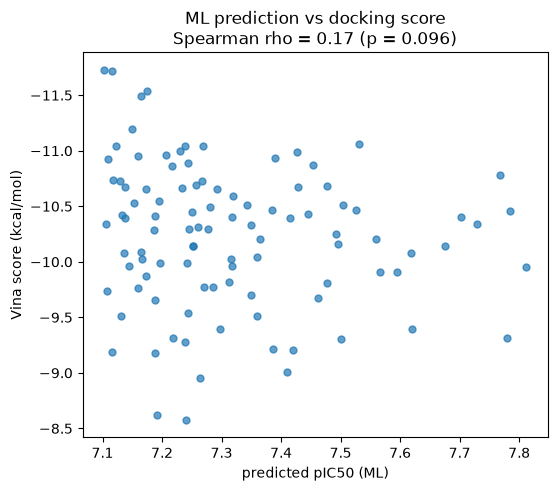

Spearman correlation between the two rankings: rho = 0.17, p = 0.096


In [21]:
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

rho, pvalue = spearmanr(results["pred_pIC50"], results["vina_score"])

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(results["pred_pIC50"], results["vina_score"], s=25, alpha=0.7)
ax.set_xlabel("predicted pIC50 (ML)")
ax.set_ylabel("Vina score (kcal/mol)")
ax.set_title(f"ML prediction vs docking score\nSpearman rho = {rho:.2f} (p = {pvalue:.3f})")
ax.invert_yaxis()  # more negative (better) docking scores at the top
fig.savefig(DATA / "ml_vs_docking.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Spearman correlation between the two rankings: rho = {rho:.2f}, p = {pvalue:.3f}")

# Batch docking: the top 100 random compounds

The cells above dock a single ligand. This section docks the **top 100 compounds by predicted
pIC50** from the step 6 ML predictions (`random_zinc22.csv`), so the
ML ranking can be compared with the docking ranking.

The receptor and docking box are prepared once and reused for every compound, so all 100
are docked under identical conditions. Unlike the single-ligand run, the receptor files are
**not** copied into each compound's folder (that would waste ~120 MB); they stay in
`docking/prepared/6CM4/`.

In [18]:
import pandas as pd

DATA = ROOT / "results" / "tables"

N_COMPOUNDS = 100
BATCH_DIR = RUN_DIR / "batch_top100"
BATCH_DIR.mkdir(parents=True, exist_ok=True)

predictions = pd.read_csv(DATA / "random_zinc22_predicted_pIC50.csv")
top_compounds = predictions.nlargest(N_COMPOUNDS, "pred_pIC50").reset_index(drop=True)

print(f"{len(top_compounds)} compounds to dock")
print(f"predicted pIC50 range: {top_compounds['pred_pIC50'].min():.2f} - "
      f"{top_compounds['pred_pIC50'].max():.2f}")
top_compounds[["compound_id", "smiles", "pred_pIC50"]].head()

100 compounds to dock
predicted pIC50 range: 6.43 - 6.91


,compound_id,smiles,pred_pIC50
0,ZINCtQ00000Sk0Ja,Fc1cccc2[nH]c(=NCCCCN3CCC3)[nH]c(=NC[C@H]3CCCS...,6.911378
1,ZINCtQ00000Sk0Jb,Fc1cccc2[nH]c(=NCCCCN3CCC3)[nH]c(=N[C@@H]3CC[C...,6.888997
2,ZINCtl00001UEXnE,CN1CCC[C@H](CNc2c(NC[C@@H]3CCN(C)c4ccccc43)c(=...,6.708235
3,ZINCtT00000Sk0J9,Fc1cccc2[nH]c(=NCC=CCl)nc(N3CCN(Cc4ccc(Cl)s4)C...,6.662403
4,ZINCtt00000xdVjk,COC(=O)C12CCCC(NC(=O)[C@H](C)N3CCN(c4ccccc4F)C...,6.660748


In [19]:
def dock_one_smiles(smiles, name, tools, receptor_pdbqt, center, size):
    """Dock a single SMILES against the shared receptor. Returns the best Vina score."""
    ligand_sdf = BATCH_DIR / f"{name}_3d.sdf"
    ligand_pdbqt = BATCH_DIR / f"{name}.pdbqt"
    poses_pdbqt = BATCH_DIR / f"{name}_poses.pdbqt"
    log_path = BATCH_DIR / f"{name}.log"

    # Same preparation as the single-ligand run: write the SMILES to a file first
    smi_path = BATCH_DIR / f"{name}.smi"
    smi_path.write_text(smiles + "\n", encoding="ascii")
    create_ligand_sdf(smi_path, ligand_sdf)

    subprocess.run(
        [tools["mk_prepare_ligand.py"], "-i", str(ligand_sdf), "-o", str(ligand_pdbqt)],
        check=True, capture_output=True,
    )

    from vina import Vina

    vina = Vina(sf_name="vina", cpu=0, verbosity=0)
    vina.set_receptor(str(receptor_pdbqt))
    vina.set_ligand_from_file(str(ligand_pdbqt))
    vina.compute_vina_maps(center=center, box_size=size)
    vina.dock(exhaustiveness=EXHAUSTIVENESS, n_poses=NUM_MODES)
    vina.write_poses(str(poses_pdbqt), n_poses=NUM_MODES, overwrite=True)

    # The best score is stored in the first pose of the output file
    for line in poses_pdbqt.read_text().splitlines():
        if line.startswith("REMARK VINA RESULT:"):
            return float(line.split()[3])
    return None

In [20]:
%conda install -c conda-forge vina meeko rdkit biopython pdbfixer openmm

zsh:1: command not found: conda

Note: you may need to restart the kernel to use updated packages.


In [21]:
%%time
tools = require_dependencies()
center, size = prepare_shared_receptor(tools)
receptor_pdbqt = SHARED_RECEPTOR_DIR / "drd2.pdbqt"

scores = []
for i, row in top_compounds.iterrows():
    try:
        score = dock_one_smiles(row["smiles"], row["compound_id"], tools,
                                receptor_pdbqt, center, size)
    except (ValueError, subprocess.CalledProcessError) as exc:
        print(f"  {row['compound_id']}: failed ({exc})")
        score = None
    scores.append(score)
    if (i + 1) % 10 == 0:
        print(f"  docked {i + 1}/{len(top_compounds)}")

top_compounds["vina_score"] = scores
print(f"\nDocked {top_compounds['vina_score'].notna().sum()} of {len(top_compounds)} compounds")

CPU times: user 189 ms, sys: 60.7 ms, total: 249 ms
Wall time: 378 ms


RuntimeError: A required package is missing. Activate the Vina environment and run:
  conda install -c conda-forge vina meeko rdkit biopython pdbfixer openmm
Then run this script again with `python vina_autodock.py`.